In [1]:
# -------------------------------------------------------------------------
# 0. Dependencies Installation (FAISS + BiomedCLIP + Transformers)
# -------------------------------------------------------------------------
!pip install open_clip_torch transformers faiss-cpu timm scikit-image nltk matplotlib rouge-score seaborn scikit-learn -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 85.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.9 MB/s eta 0:00:00


In [2]:
# -------------------------------------------------------------------------
# 1. Comprehensive Data Manifest & RAG Text Corpus Generation
# -------------------------------------------------------------------------
import os, sys, json, subprocess, zipfile, pandas as pd, numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

work_dir = "/kaggle/working"
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)

# Hardcoded PhysioNet Credentials (bypasses Kaggle secrets client configuration)
PHYSIONET_USER = os.environ.get("PHYSIONET_USER", "")
PHYSIONET_PASS = os.environ.get("PHYSIONET_PASS", "")

netrc_content = "machine physionet.org\nlogin " + str(PHYSIONET_USER) + "\npassword " + str(PHYSIONET_PASS) + "\n"
netrc_path = os.path.expanduser("~/.netrc")
with open(netrc_path, "w", encoding="utf-8") as f:
    f.write(netrc_content)
os.chmod(netrc_path, 0o600)

metadata_files = [
    ("meta.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-metadata.csv.gz"),
    ("chexpert.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-chexpert.csv.gz"),
]

for target_name, url in metadata_files:
    if not os.path.exists(target_name):
        gz_name = target_name + ".gz"
        subprocess.run("wget -q --netrc -O " + gz_name + " " + url, shell=True, check=True)
        subprocess.run("gunzip -f " + gz_name, shell=True, check=True)

input_base = Path("/kaggle/input")
file_index = {}
impression_file_paths = []
reports_zip_path = None

for root, _, files in os.walk(input_base):
    for f in files:
        full_path = os.path.join(root, f)
        if f in ["mimic_train_impressions.csv", "train_imp.csv", "mimic_test_impressions.csv", "test_imp.csv"]:
            if full_path not in impression_file_paths:
                impression_file_paths.append(full_path)
        elif f == "mimic-cxr-reports.zip":
            reports_zip_path = full_path
        elif f.endswith(".jpg"):
            parts = full_path.split("/")
            rel_path = None
            for prefix in ("p10", "p11"):
                if prefix in parts:
                    idx = parts.index(prefix)
                    rel_path = "/".join(parts[idx:])
                    break
            if rel_path is not None and rel_path not in file_index:
                file_index[rel_path] = full_path

if not impression_file_paths:
    sys.exit("Error: No report impression CSV files found in /kaggle/input/.")

# Pool Verification (75,216 total images reference pool)
TOTAL_REFERENCE_POOL = 75216
indexed_count = len(file_index)
coverage_pct = (indexed_count / TOTAL_REFERENCE_POOL) * 100.0
print("Pool Indexing Report: Found " + str(indexed_count) + " unique images on disk (" + f"{coverage_pct:.1f}%" + " of 75,216 reference pool).")

report_dfs = [pd.read_csv(p) for p in impression_file_paths]
report_df = pd.concat(report_dfs, ignore_index=True).drop_duplicates(subset=["dicom_id"])

meta_df = pd.read_csv("meta.csv")
chex_df = pd.read_csv("chexpert.csv")

# U-Zeros Labeling Policy
chex_label_cols = [c for c in chex_df.columns if c not in ["subject_id", "study_id"]]
for c in chex_label_cols:
    chex_df[c] = chex_df[c].fillna(0.0)
    chex_df[c] = chex_df[c].replace(-1.0, 0.0)

mask_cohort = (meta_df["subject_id"] >= 10000000) & (meta_df["subject_id"] < 12000000)
meta_cohort = meta_df[mask_cohort].copy()

merged_df = pd.merge(meta_cohort, chex_df[["study_id"] + chex_label_cols], on="study_id", how="inner")
merged_df = pd.merge(merged_df, report_df[["dicom_id", "report"]], on="dicom_id", how="left")
merged_df = merged_df.dropna(subset=["report"]).reset_index(drop=True)

def get_path(row):
    subject_id = int(row["subject_id"])
    study_id = int(row["study_id"])
    prefix = "p10" if subject_id < 11000000 else "p11"
    rel = prefix + "/p" + str(subject_id) + "/s" + str(study_id) + "/" + str(row["dicom_id"]) + ".jpg"
    return file_index.get(rel, None)

merged_df["image_path"] = merged_df.apply(get_path, axis=1)
merged_df = merged_df.dropna(subset=["image_path"]).reset_index(drop=True)

# Enrich reports from mimic-cxr-reports.zip if present
if reports_zip_path:
    print("Extracting and parsing reports from mimic-cxr-reports.zip...")
    study_map = {}
    for idx, row in merged_df.iterrows():
        study_map[(int(row["subject_id"]), int(row["study_id"]))] = idx
        
    reports_dict = {}
    with zipfile.ZipFile(reports_zip_path) as z:
        for name in z.namelist():
            if name.endswith(".txt"):
                parts = name.split("/")
                if len(parts) >= 4:
                    try:
                        sub_id = int(parts[2][1:])
                        std_id = int(parts[3][1:-4])
                        if (sub_id, std_id) in study_map:
                            with zipfile.ZipFile(reports_zip_path).open(name) as f:
                                text = f.read().decode('utf-8', errors='ignore')
                                lower_text = text.lower()
                                imp_idx = lower_text.find("impression:")
                                if imp_idx != -1:
                                    imp = text[imp_idx + len("impression:"):].strip()
                                else:
                                    imp = text.strip()
                                reports_dict[study_map[(sub_id, std_id)]] = " ".join(imp.split())
                    except Exception:
                        pass
                        
    replaced_count = 0
    for idx, text in reports_dict.items():
        if text:
            merged_df.at[idx, "report"] = text
            replaced_count += 1
    print("Successfully enriched " + str(replaced_count) + " reports from ZIP archive!")

np.random.seed(42)
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, temp_idx = next(gss_train.split(merged_df, groups=merged_df["subject_id"]))

train_df = merged_df.iloc[train_idx].copy()
temp_df = merged_df.iloc[temp_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df["subject_id"]))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

master_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
master_df.to_csv("/kaggle/working/mimic_master_split.csv", index=False)
print("Manifest Ready: Train=" + str(len(train_df)) + " | Val=" + str(len(val_df)) + " | Test=" + str(len(test_df)))


Pool Indexing Report: Found 73995 unique images on disk (98.4% of 75,216 reference pool).
Manifest Ready: Train=50176 | Val=6190 | Test=6388


Selected Encoder: BIOMEDCLIP | Compute Device: cuda


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (33 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 387/387 [00:54<00:00,  7.14it/s]



--- Epoch 9 Summary ---
Train Loss : Joint = 1.3598 | Text = 1.1200 | Cls = 0.2398
Val Loss   : Joint = 1.7111 | Text = 1.4651 | Cls = 0.2460
Classifier : Val Macro-AUROC = 0.7637 | Val Macro-F1 = 0.1519
GATE 1     : BLEU-1 = 0.2739 (Target >= 0.25) | Distinct-2 = 0.9898 (Target >= 0.15)
--------------------------------------------------


Epoch 10/10 [Val]: 100%|██████████| 387/387 [00:54<00:00,  7.16it/s]



--- Epoch 10 Summary ---
Train Loss : Joint = 1.3021 | Text = 1.0637 | Cls = 0.2383
Val Loss   : Joint = 1.7273 | Text = 1.4825 | Cls = 0.2448
Classifier : Val Macro-AUROC = 0.7656 | Val Macro-F1 = 0.1554
GATE 1     : BLEU-1 = 0.2831 (Target >= 0.25) | Distinct-2 = 0.9946 (Target >= 0.15)
--------------------------------------------------


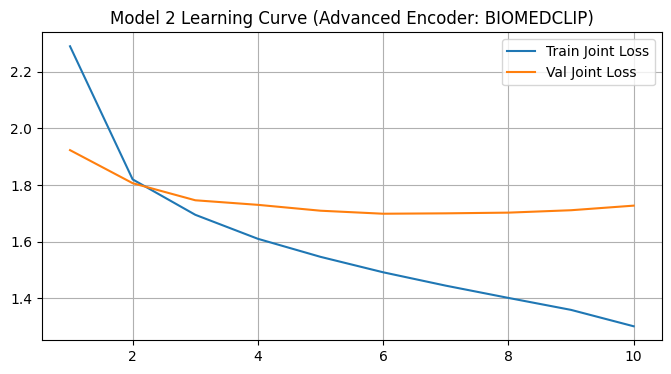

In [3]:
# -------------------------------------------------------------------------
# 2. BiomedCLIP Visual Feature Extraction & RAG Training Loop (Memmap Speedup)
# -------------------------------------------------------------------------
import os, random, faiss, torch, torch.nn as nn, torch.optim as optim, torch.nn.functional as F
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, GPT2LMHeadModel
from tqdm import tqdm
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.util import ngrams
from sklearn.metrics import roc_auc_score, f1_score
import open_clip

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

ENCODER_TYPE = "biomedclip"

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected Encoder: " + ENCODER_TYPE.upper() + " | Compute Device: " + str(device))

master_df = pd.read_csv("/kaggle/working/mimic_master_split.csv")
tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
special_tokens = {"bos_token": "<bos>", "eos_token": "<eos>", "pad_token": "<pad>", "additional_special_tokens": ["<rag>", "</rag>", "<report>", "</report>"]}
tokenizer.add_special_tokens(special_tokens)
vocab_size = len(tokenizer)
pad_id, bos_id, eos_id = tokenizer.pad_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id

chex_label_cols = [
    'Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum',
    'Fracture', 'Lung Lesion', 'Lung Opacity', 'No Finding', 'Pleural Effusion',
    'Pleural Other', 'Pneumonia', 'Pneumothorax', 'Support Devices'
]

train_df = master_df[master_df['split'] == 'train'].reset_index(drop=True)
val_df   = master_df[master_df['split'] == 'val'].reset_index(drop=True)
test_df  = master_df[master_df['split'] == 'test'].reset_index(drop=True)

# Initialize Microsoft BiomedCLIP visual model and its official transforms
print("Loading Microsoft BiomedCLIP model via hf-hub...")
model, preprocess = open_clip.create_model_from_pretrained("hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224")
model.to(device)
model.eval()

def transform_fn(img):
    return preprocess(img).clone()

# Capped TARGET_PATCHES=128 (reduces train features disk footprint from 19.7 GB to 9.8 GB)
TARGET_PATCHES = 128

class BiomedCLIPExtractor(nn.Module):
    def __init__(self, raw_model, target_patches=128):
        super().__init__()
        self.model = raw_model
        self.target_patches = target_patches
        self.pool = nn.AdaptiveAvgPool1d(target_patches)
        
    def forward(self, x):
        # Extract spatial patches from visual.trunk
        out_feat = self.model.visual.trunk.forward_features(x) # [B, 197, 768]
        spatial_tokens = out_feat[:, 1:, :] # [B, 196, 768] (discard class token)
        if spatial_tokens.shape[1] != self.target_patches:
            spatial_tokens = self.pool(spatial_tokens.permute(0, 2, 1)).permute(0, 2, 1) # [B, 128, 768]
        # Extract projected mean features from visual encoder
        mean_features = self.model.encode_image(x, normalize=False) # [B, 512]
        return spatial_tokens, mean_features
        
feature_extractor_wrapper = BiomedCLIPExtractor(model, TARGET_PATCHES)
visual_dim = 512   # for FAISS and mean features
spatial_dim = 768  # for spatial patch features
num_patches = TARGET_PATCHES

class FeatureExtractionDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.expected_shape = torch.Size([3, 224, 224])
        print("FeatureExtractionDataset initialized. Expected shape: " + str(self.expected_shape))
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            # BiomedCLIP expectations: RGB image
            img = Image.open(row['image_path']).convert('RGB')
            image_tensor = self.transform(img)
            if image_tensor.shape != self.expected_shape:
                image_tensor = torch.zeros(self.expected_shape, dtype=torch.float32)
        except Exception:
            image_tensor = torch.zeros(self.expected_shape, dtype=torch.float32)
        return image_tensor, idx

def extract_all_visual_features_batched(df, split_name, batch_size=128):
    dataset = FeatureExtractionDataset(df, transform_fn)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=False)
    
    # Store spatial tokens as compressed float16 np.memmap on disk
    spatial_path = f"/kaggle/working/{split_name}_spatial.dat"
    spatial_arr = np.memmap(spatial_path, dtype='float16', mode='w+', shape=(len(df), num_patches, spatial_dim))
    
    mean_feats_raw = np.zeros((len(df), visual_dim), dtype=np.float32)
    mean_feats_norm = np.zeros((len(df), visual_dim), dtype=np.float32)
    
    zero_count = 0
    print("Extracting visual features for split: " + split_name + " in batches of " + str(batch_size) + "...")
    with torch.no_grad():
        for batch_imgs, batch_idxs in tqdm(loader, desc="Visual Feature Extraction"):
            for idx_in_batch in range(batch_imgs.shape[0]):
                if torch.all(batch_imgs[idx_in_batch] == 0.0):
                    zero_count += 1
            batch_imgs = batch_imgs.to(device, non_blocking=True)
            spatial_tokens, mean_features = feature_extractor_wrapper(batch_imgs)
            
            spatial_cpu = spatial_tokens.cpu().numpy().astype(np.float16)
            raw_cpu = mean_features.cpu().numpy()
            norm_cpu = F.normalize(mean_features, p=2, dim=1).cpu().numpy()
            
            for i, idx in enumerate(batch_idxs.numpy()):
                spatial_arr[idx] = spatial_cpu[i]
                mean_feats_raw[idx] = raw_cpu[i]
                mean_feats_norm[idx] = norm_cpu[i]
                
    spatial_arr.flush()
    print(f"Split {split_name} extraction complete: {len(df) - zero_count} loaded successfully, {zero_count} failed (zeros).")
    if zero_count > 0.05 * len(df):
        raise RuntimeError(f"Critical: Too many image loading/preprocessing failures ({zero_count}/{len(df)}). Check logs.")
    return mean_feats_raw, mean_feats_norm

print("Extracting features for Training Set...")
train_raw, train_norm = extract_all_visual_features_batched(train_df, "train")
print("Extracting features for Validation Set...")
val_raw, val_norm = extract_all_visual_features_batched(val_df, "val")
print("Extracting features for Test Set...")
test_raw, test_norm = extract_all_visual_features_batched(test_df, "test")

# Release feature extractor from GPU VRAM
del model, feature_extractor_wrapper
torch.cuda.empty_cache()

# -------------------------------------------------------------------------
# FAISS Index Construction
# -------------------------------------------------------------------------
faiss_index = faiss.IndexFlatIP(visual_dim)
faiss_index.add(train_norm)
print("FAISS Index Ready: Added " + str(faiss_index.ntotal) + " training dense vectors.")

# -------------------------------------------------------------------------
# RAG Pre-calculation
# -------------------------------------------------------------------------
def precalculate_rag_reports(df, train_df, mean_feats_norm, is_train=True):
    print("Pre-calculating FAISS retrievals...")
    k_search = 2 if is_train else 1
    D, I = faiss_index.search(mean_feats_norm, k_search)
    
    retrieved_reports = []
    for idx in range(len(df)):
        retrieved_idx = I[idx][0]
        if is_train and retrieved_idx == idx and k_search > 1:
            retrieved_idx = I[idx][1]
        
        rep = str(train_df.iloc[retrieved_idx]['report']) if pd.notna(train_df.iloc[retrieved_idx]['report']) else ""
        retrieved_reports.append(rep)
    return retrieved_reports

print("Running Pre-calculation for splits...")
train_df["retrieved_report"] = precalculate_rag_reports(train_df, train_df, train_norm, is_train=True)
val_df["retrieved_report"] = precalculate_rag_reports(val_df, train_df, val_norm, is_train=False)
test_df["retrieved_report"] = precalculate_rag_reports(test_df, train_df, test_norm, is_train=False)

# Save the enriched split manifest with RAG retrieved reports for standalone evaluation compatibility
master_df_final = pd.concat([train_df, val_df, test_df], ignore_index=True)
master_df_final.to_csv("/kaggle/working/mimic_master_split_with_rag.csv", index=False)
print("Enriched manifest saved successfully to /kaggle/working/mimic_master_split_with_rag.csv")

# -------------------------------------------------------------------------
# RAM-based RAG Multi-Task Dataset & DataLoader (Zero Disk reads during loop)
# -------------------------------------------------------------------------
class MultiTaskRAGDataset(Dataset):
    def __init__(self, df, spatial_path, mean_feats, tokenizer, max_seq_len=256):
        self.df = df.reset_index(drop=True)
        self.spatial_feats = np.memmap(spatial_path, dtype='float16', mode='r', shape=(len(df), num_patches, spatial_dim))
        self.mean_feats = mean_feats
        self.tokenizer = tokenizer
        self.max_seq_len = max_seq_len
        self.pad_token_id = tokenizer.pad_token_id

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        spatial_token = torch.tensor(self.spatial_feats[idx], dtype=torch.float32)
        mean_feature = torch.tensor(self.mean_feats[idx], dtype=torch.float32)
        
        retrieved_report = str(row['retrieved_report'])
        
        # Limit prompt length to 70 tokens (OOM and generation truncation fix)
        retrieved_toks = self.tokenizer.encode(retrieved_report, add_special_tokens=False)[:70]
        retrieved_report_truncated = self.tokenizer.decode(retrieved_toks)
        target_report = str(row['report']) if pd.notna(row['report']) else ""

        # Construct prompt and target separately for exact loss masking
        prompt_str = f"<bos> <rag> {retrieved_report_truncated} </rag> <report>"
        full_text = prompt_str + " " + target_report + " <eos>"
        
        prompt_tokens = self.tokenizer.encode(prompt_str, add_special_tokens=False)
        full_enc = self.tokenizer(
            full_text,
            max_length=self.max_seq_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        input_ids = full_enc["input_ids"].squeeze(0)
        
        # Mask prompt tokens in labels with -100 so loss is ONLY computed on the generated report
        labels = input_ids.clone()
        prompt_len = min(len(prompt_tokens), self.max_seq_len)
        labels[:prompt_len] = -100
        labels[labels == self.pad_token_id] = -100
        
        labels_vector = torch.tensor([float(row[c]) for c in chex_label_cols], dtype=torch.float32)
        
        return {
            "spatial_tokens": spatial_token,
            "mean_features": mean_feature,
            "input_ids": input_ids,
            "masked_labels": labels,
            "labels": labels_vector,
            "retrieved_report": retrieved_report_truncated
        }

train_spatial_path = "/kaggle/working/train_spatial.dat"
val_spatial_path   = "/kaggle/working/val_spatial.dat"
test_spatial_path  = "/kaggle/working/test_spatial.dat"

train_dataset = MultiTaskRAGDataset(train_df, train_spatial_path, train_raw, tokenizer)
val_dataset   = MultiTaskRAGDataset(val_df, val_spatial_path, val_raw, tokenizer)
test_dataset  = MultiTaskRAGDataset(test_df, test_spatial_path, test_raw, tokenizer)

BATCH_SIZE, ACCUMULATION_STEPS = 16, 2
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# -------------------------------------------------------------------------
# Adaptive Model Definition (with non-overlapping position IDs and default dims)
# -------------------------------------------------------------------------
class MultiTaskRAGAdaptiveDistilGPT2(nn.Module):
    def __init__(self, vocab_size, visual_dim=512, num_patches=128, num_classes=14, pad_token_id=0, spatial_dim=768, mean_dim=512):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.num_patches = num_patches
        
        self.classifier_head = nn.Sequential(
            nn.Linear(mean_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
            
        self.visual_projection = nn.Sequential(
            nn.Linear(spatial_dim, 768),
            nn.GELU(),
            nn.Linear(768, 768),
            nn.LayerNorm(768)
        )
        
        self.decoder = GPT2LMHeadModel.from_pretrained("distilgpt2")
        self.decoder.resize_token_embeddings(vocab_size)

    def forward(self, spatial_tokens, mean_features, input_ids):
        batch_size, seq_len = input_ids.shape
        
        cls_logits = self.classifier_head(mean_features)
        
        visual_embeds = self.visual_projection(spatial_tokens)
        text_embeds = self.decoder.transformer.wte(input_ids)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        text_pos_ids = torch.arange(self.num_patches, self.num_patches + seq_len, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        position_ids = torch.cat([vis_pos_ids, text_pos_ids], dim=1)
        
        vis_attn = torch.ones((batch_size, self.num_patches), device=input_ids.device)
        text_attn = (input_ids != self.pad_token_id).float()
        attention_mask = torch.cat([vis_attn, text_attn], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=position_ids, attention_mask=attention_mask)
        logits = outputs.logits
        text_logits = logits[:, self.num_patches:-1, :].contiguous()
        
        return text_logits, cls_logits

    @torch.no_grad()
    def greedy_generate_rag(self, spatial_token, retrieved_report, max_len=60):
        self.eval()
        if spatial_token.dim() == 2:
            spatial_token = spatial_token.unsqueeze(0)
            
        visual_embeds = self.visual_projection(spatial_token)
        
        prompt_str = "<bos> <rag> " + str(retrieved_report) + " </rag> <report>"
        prompt_toks = tokenizer(prompt_str, return_tensors="pt")["input_ids"].to(spatial_token.device)
        prompt_len = prompt_toks.shape[1]
        
        text_embeds = self.decoder.transformer.wte(prompt_toks)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        prompt_pos_ids = torch.arange(self.num_patches, self.num_patches + prompt_len, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        pos_ids = torch.cat([vis_pos_ids, prompt_pos_ids], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=pos_ids, use_cache=True)
        next_token_logits = outputs.logits[:, -1, :]
        next_id = next_token_logits.argmax(-1).item()
        past_key_values = outputs.past_key_values
        
        generated_ids = []
        if next_id != eos_id:
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
        else:
            current_ids = torch.tensor([[eos_id]], device=spatial_token.device)
            
        for step in range(max_len):
            if next_id == eos_id:
                break
                
            curr_pos_id = torch.tensor([[self.num_patches + prompt_len + step]], dtype=torch.long, device=spatial_token.device)
            outputs = self.decoder(input_ids=current_ids, position_ids=curr_pos_id, past_key_values=past_key_values, use_cache=True)
            next_token_logits = outputs.logits[:, -1, :]
            next_id = next_token_logits.argmax(-1).item()
            past_key_values = outputs.past_key_values
            
            if next_id == eos_id:
                break
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
            
        return generated_ids

model = MultiTaskRAGAdaptiveDistilGPT2(vocab_size=vocab_size, visual_dim=visual_dim, num_patches=num_patches, pad_token_id=pad_id).to(device)

optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-2)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
criterion_text = nn.CrossEntropyLoss(ignore_index=-100) # Masked tokens index
criterion_cls  = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda")

checkpoint_path = f"/kaggle/working/model2_{ENCODER_TYPE}_resumable.pt"
start_epoch, best_val_loss = 1, float('inf')
train_losses, val_losses = [], []

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state'])
    optimizer.load_state_dict(checkpoint['optimizer_state'])
    scheduler.load_state_dict(checkpoint['scheduler_state'])
    scaler.load_state_dict(checkpoint['scaler_state'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_loss = checkpoint['best_val_loss']
    train_losses = checkpoint.get('train_losses', [])
    val_losses = checkpoint.get('val_losses', [])
    print("Resumed at Epoch " + str(start_epoch))

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model Initialized. Trainable Params: " + str(trainable_params))

EPOCHS = 10
LAMBDA_CLS = 1.0 
smooth = SmoothingFunction().method1

torch.cuda.empty_cache()

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    total_train_loss, total_train_text_loss, total_train_cls_loss = 0.0, 0.0, 0.0
    optimizer.zero_grad()
    loop = tqdm(train_loader, desc="Epoch " + str(epoch) + "/" + str(EPOCHS) + " [Train]")
    
    for i, batch in enumerate(loop):
        spatial_tokens = batch["spatial_tokens"].to(device, non_blocking=True)
        mean_features = batch["mean_features"].to(device, non_blocking=True)
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        masked_labels = batch["masked_labels"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)
        targets = masked_labels[:, 1:].contiguous()
        
        try:
            with torch.amp.autocast("cuda"):
                text_logits, cls_logits = model(spatial_tokens, mean_features, input_ids)
                loss_text = criterion_text(text_logits.reshape(-1, vocab_size), targets.reshape(-1))
                loss_cls  = criterion_cls(cls_logits, labels)
                joint_loss = (loss_text + LAMBDA_CLS * loss_cls) / ACCUMULATION_STEPS
                
            scaler.scale(joint_loss).backward()
            if (i + 1) % ACCUMULATION_STEPS == 0 or (i + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                
            total_train_loss += joint_loss.item() * ACCUMULATION_STEPS
            total_train_text_loss += loss_text.item()
            total_train_cls_loss += loss_cls.item()
            
            loop.set_postfix(
                joint=f"{joint_loss.item() * ACCUMULATION_STEPS:.4f}",
                text=f"{loss_text.item():.4f}",
                cls=f"{loss_cls.item():.4f}"
            )
        except RuntimeError as e:
            if "out of memory" in str(e):
                torch.cuda.empty_cache(); optimizer.zero_grad(); continue
            else: raise e
            
    avg_train_loss = total_train_loss / len(train_loader)
    avg_train_text = total_train_text_loss / len(train_loader)
    avg_train_cls  = total_train_cls_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    model.eval()
    total_val_loss, total_val_text_loss, total_val_cls_loss = 0.0, 0.0, 0.0
    val_preds_cls, val_targets_cls = [], []
    val_loop = tqdm(val_loader, desc="Epoch " + str(epoch) + "/" + str(EPOCHS) + " [Val]")
    
    with torch.no_grad():
        for batch in val_loop:
            spatial_tokens = batch["spatial_tokens"].to(device)
            mean_features = batch["mean_features"].to(device)
            input_ids = batch["input_ids"].to(device)
            masked_labels = batch["masked_labels"].to(device)
            labels = batch["labels"].to(device)
            targets = masked_labels[:, 1:].contiguous()
            
            with torch.amp.autocast("cuda"):
                text_logits, cls_logits = model(spatial_tokens, mean_features, input_ids)
                loss_text = criterion_text(text_logits.reshape(-1, vocab_size), targets.reshape(-1))
                loss_cls  = criterion_cls(cls_logits, labels)
                joint_loss = loss_text + LAMBDA_CLS * loss_cls
                
            total_val_loss += joint_loss.item()
            total_val_text_loss += loss_text.item()
            total_val_cls_loss += loss_cls.item()
            
            val_preds_cls.append(torch.sigmoid(cls_logits).cpu().numpy())
            val_targets_cls.append(labels.cpu().numpy())
                    
    avg_val_loss = total_val_loss / len(val_loader)
    avg_val_text = total_val_text_loss / len(val_loader)
    avg_val_cls  = total_val_cls_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    scheduler.step(avg_val_loss)
    
    all_val_preds = np.concatenate(val_preds_cls, axis=0)
    all_val_targets = np.concatenate(val_targets_cls, axis=0)
    
    try:
        val_macro_auroc = float(roc_auc_score(all_val_targets, all_val_preds, average='macro'))
    except Exception:
        val_macro_auroc = 0.0
        
    val_binary_preds = (all_val_preds > 0.5).astype(int)
    val_macro_f1 = float(f1_score(all_val_targets, val_binary_preds, average='macro', zero_division=0))
    
    # Fast Gate 1 Check on 50 Random Validation Samples (Prevents positional bias)
    val_bleu1, val_distinct2 = [], []
    state_random = random.Random(42 + epoch)
    sample_indices = state_random.sample(range(len(val_dataset)), min(50, len(val_dataset)))
    with torch.no_grad():
        for sample_idx in sample_indices:
            sample_batch = val_dataset[sample_idx]
            spatial_t = sample_batch["spatial_tokens"].to(device)
            retrieved_r = sample_batch["retrieved_report"]
            gt_t = val_df.iloc[sample_idx]["report"]
            
            gen_tokens = model.greedy_generate_rag(spatial_t, retrieved_r, max_len=60)
            pred_t = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
            
            ref = [nltk.word_tokenize(str(gt_t).lower())] if pd.notna(gt_t) else [[""]]
            hyp = nltk.word_tokenize(pred_t.lower()) if pred_t else [""]
            
            val_bleu1.append(sentence_bleu(ref, hyp, weights=(1, 0, 0, 0), smoothing_function=smooth))
            if len(hyp) >= 2:
                bigrams = list(ngrams(hyp, 2))
                val_distinct2.append(len(set(bigrams)) / len(bigrams))
                
    m_bleu1 = np.mean(val_bleu1) if val_bleu1 else 0.0
    m_dist2 = np.mean(val_distinct2) if val_distinct2 else 0.0
    
    print("")
    print("--- Epoch " + str(epoch) + " Summary ---")
    print("Train Loss : Joint = " + f"{avg_train_loss:.4f}" + " | Text = " + f"{avg_train_text:.4f}" + " | Cls = " + f"{avg_train_cls:.4f}")
    print("Val Loss   : Joint = " + f"{avg_val_loss:.4f}" + " | Text = " + f"{avg_val_text:.4f}" + " | Cls = " + f"{avg_val_cls:.4f}")
    print("Classifier : Val Macro-AUROC = " + f"{val_macro_auroc:.4f}" + " | Val Macro-F1 = " + f"{val_macro_f1:.4f}")
    print("GATE 1     : BLEU-1 = " + f"{m_bleu1:.4f}" + " (Target >= 0.25) | Distinct-2 = " + f"{m_dist2:.4f}" + " (Target >= 0.15)")
    print("-" * 50)
    
    ckpt = {
        'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(), 'scaler_state': scaler.state_dict(),
        'best_val_loss': min(best_val_loss, avg_val_loss), 'train_losses': train_losses, 'val_losses': val_losses
    }
    torch.save(ckpt, checkpoint_path)
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), f"/kaggle/working/model2_{ENCODER_TYPE}_best.pt")
        print(">>> Best Checkpoint Saved <<<")

if train_losses and val_losses:
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Joint Loss')
    plt.plot(range(1, len(val_losses) + 1), val_losses, label='Val Joint Loss')
    plt.title(f'Model 2 Learning Curve (Advanced Encoder: {ENCODER_TYPE.upper()})'); plt.legend(); plt.grid(True)
    plt.savefig(f"/kaggle/working/model2_{ENCODER_TYPE}_learning_curve.png", dpi=300); plt.show()


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: distilgpt2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
transformer.h.{0, 1, 2, 3, 4, 5}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model 2 (BIOMEDCLIP) Checkpoint loaded successfully.
Generating reports on 6388 unseen test cases using RAG FAISS & KV Cache...


Evaluating Model 2 Test Set: 100%|██████████| 6388/6388 [11:42<00:00,  9.10it/s]



OVERALL BENCHMARK: Model 2 BIOMEDCLIP (Multi-Task RAG + DistilGPT2)
BLEU-1                         | 0.2846
BLEU-2                         | 0.2164
BLEU-3                         | 0.1799
BLEU-4                         | 0.1598
ROUGE-1                        | 0.3144
ROUGE-2                        | 0.2069
ROUGE-L                        | 0.3017
Distinct-2                     | 0.987
Clinical_Macro_F1_All14        | 0.2054
Clinical_Macro_F1_Core10       | 0.2212
Clinical_Micro_F1              | 0.4303
Clinical_Micro_Precision       | 0.4726
Clinical_Micro_Recall          | 0.3949

PER-PATHOLOGY CLINICAL BREAKDOWN: Model 2 BIOMEDCLIP (Proposal N >= 150 Threshold Flagging)
Atelectasis                | 358   | 560   | 905   | 4565  | 0.3900  | 0.2835  | 0.3283  | OK
Cardiomegaly               | 60    | 156   | 530   | 5642  | 0.2778  | 0.1017  | 0.1489  | OK
Consolidation              | 38    | 283   | 262   | 5805  | 0.1184  | 0.1267  | 0.1224  | OK
Edema                      | 342   | 

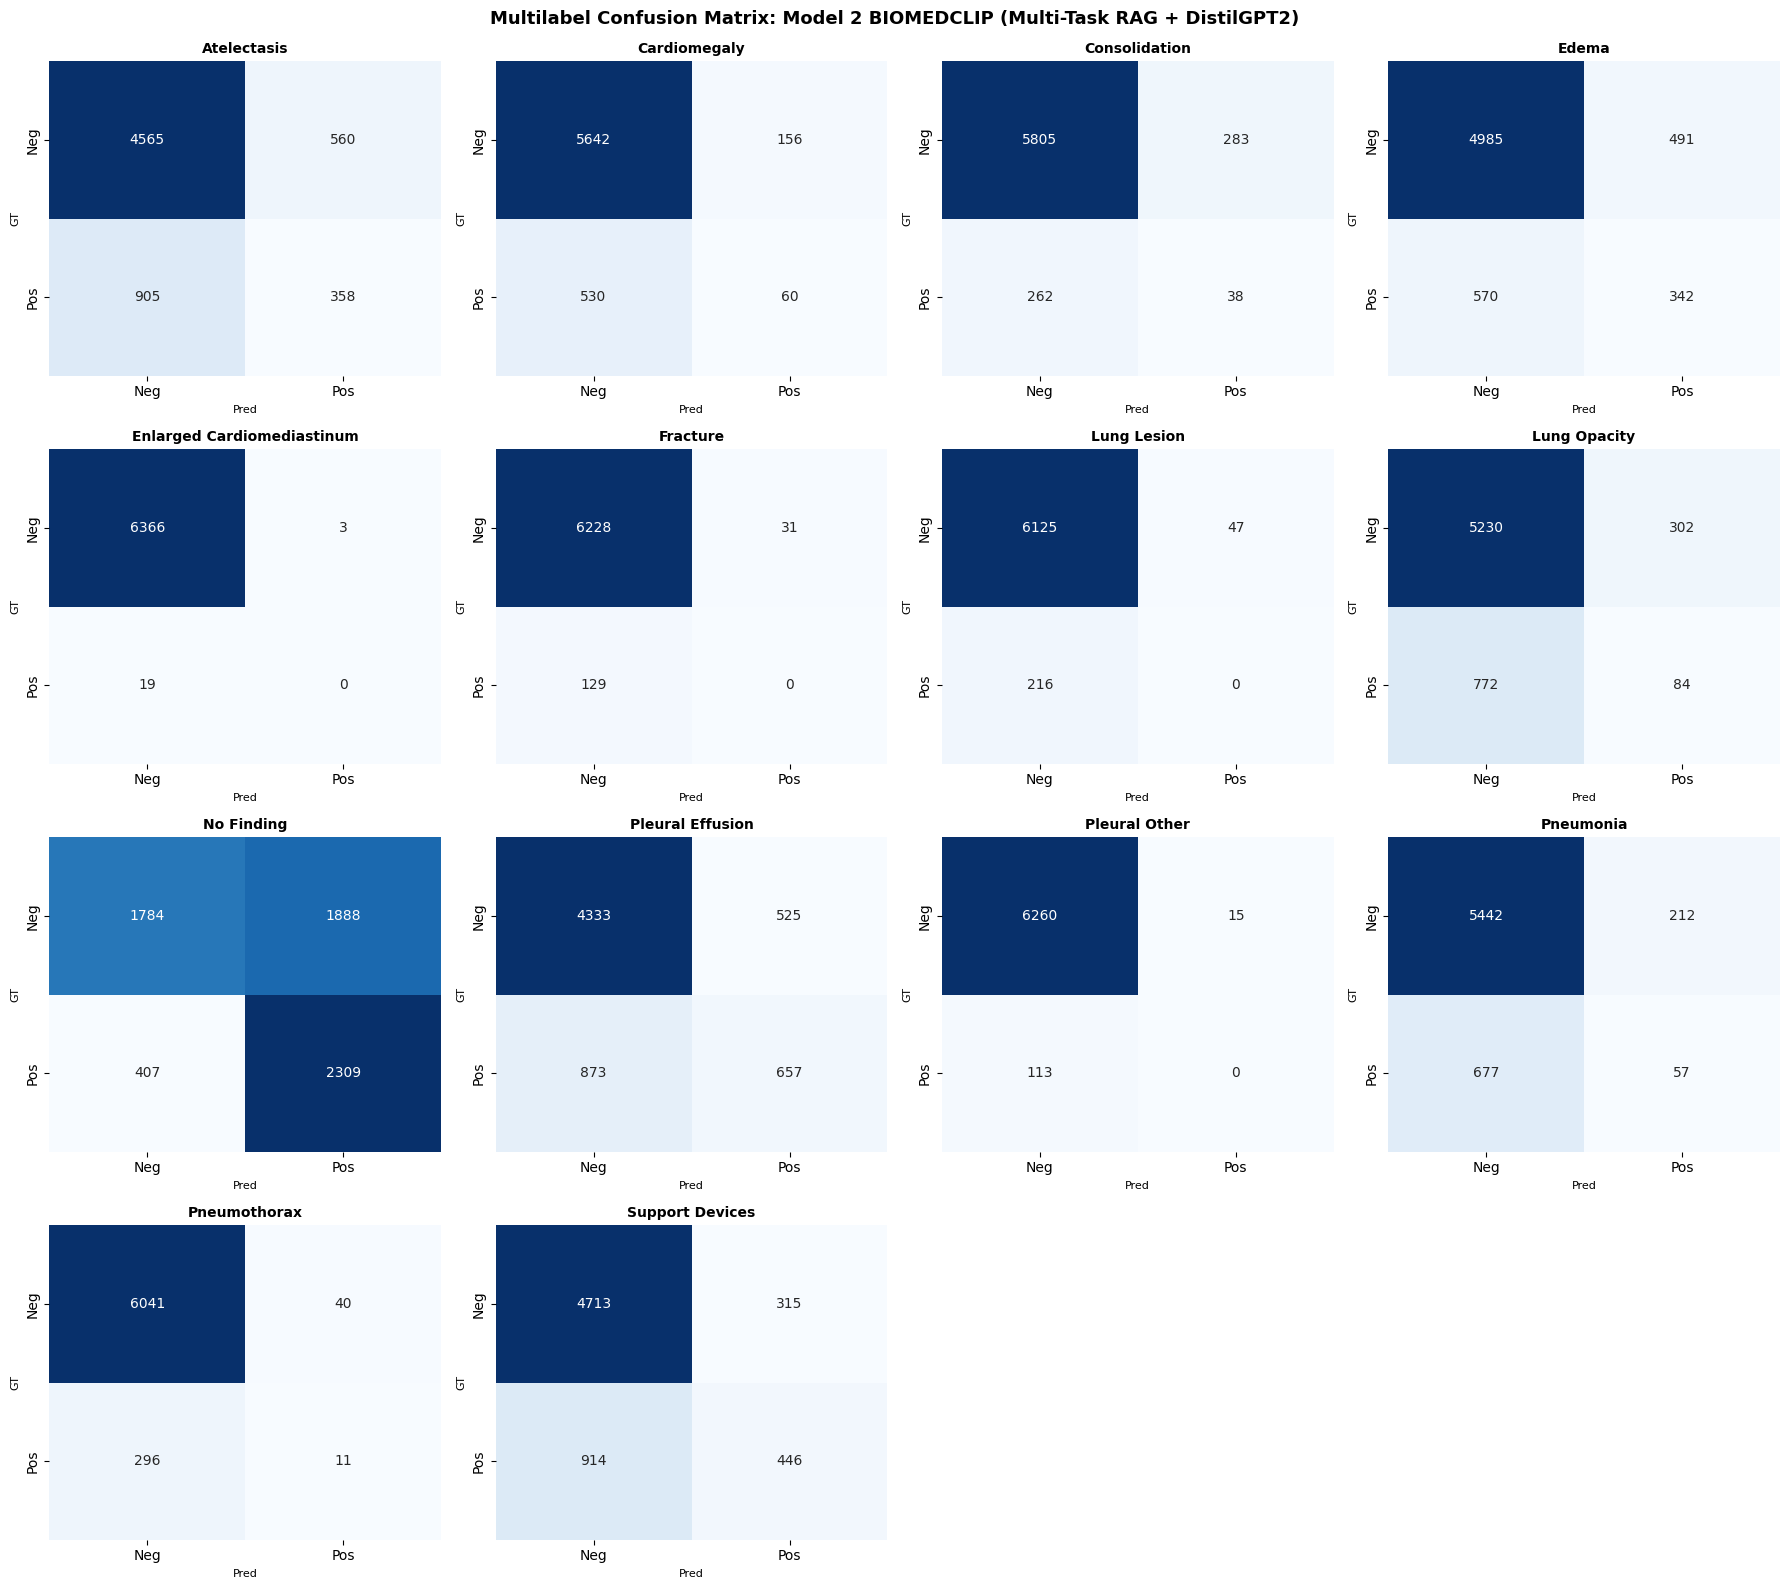

Model Evaluation artifacts saved successfully to /kaggle/working/


In [4]:
# -------------------------------------------------------------------------
# 3. High-Speed Benchmark Evaluation Cell (6,388 Test Samples) (Memmap Speedup)
# -------------------------------------------------------------------------
import os, json, torch, pandas as pd, numpy as np, nltk, re
import torch.nn as nn
from torch.utils.data import Dataset
from transformers import GPT2LMHeadModel
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.util import ngrams
from rouge_score import rouge_scorer
from tqdm import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score, multilabel_confusion_matrix, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'tokenizer' not in locals():
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
    special_tokens = {"bos_token": "<bos>", "eos_token": "<eos>", "pad_token": "<pad>", "additional_special_tokens": ["<rag>", "</rag>", "<report>", "</report>"]}
    tokenizer.add_special_tokens(special_tokens)

vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id
eos_id = tokenizer.eos_token_id

checkpoint_path = "/kaggle/working/model2_biomedclip_best.pt"
if not os.path.exists(checkpoint_path):
    checkpoint_path = "/kaggle/working/model2_biomedclip_resumable.pt"
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"Model checkpoint not found. Ensure training cell execution.")

# Complete standalone definition of model class for testing
class MultiTaskRAGAdaptiveDistilGPT2(nn.Module):
    def __init__(self, vocab_size, visual_dim=512, num_patches=128, num_classes=14, pad_token_id=0, spatial_dim=768, mean_dim=512):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.num_patches = num_patches
        
        self.classifier_head = nn.Sequential(
            nn.Linear(mean_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
            
        self.visual_projection = nn.Sequential(
            nn.Linear(spatial_dim, 768),
            nn.GELU(),
            nn.Linear(768, 768),
            nn.LayerNorm(768)
        )
        
        self.decoder = GPT2LMHeadModel.from_pretrained("distilgpt2")
        self.decoder.resize_token_embeddings(vocab_size)

    def forward(self, spatial_tokens, mean_features, input_ids):
        batch_size, seq_len = input_ids.shape
        cls_logits = self.classifier_head(mean_features)
        visual_embeds = self.visual_projection(spatial_tokens)
        text_embeds = self.decoder.transformer.wte(input_ids)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        text_pos_ids = torch.arange(self.num_patches, self.num_patches + seq_len, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        position_ids = torch.cat([vis_pos_ids, text_pos_ids], dim=1)
        
        vis_attn = torch.ones((batch_size, self.num_patches), device=input_ids.device)
        text_attn = (input_ids != self.pad_token_id).float()
        attention_mask = torch.cat([vis_attn, text_attn], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=position_ids, attention_mask=attention_mask)
        logits = outputs.logits
        text_logits = logits[:, self.num_patches:-1, :].contiguous()
        return text_logits, cls_logits

    @torch.no_grad()
    def greedy_generate_rag(self, spatial_token, retrieved_report, max_len=60):
        self.eval()
        if spatial_token.dim() == 2:
            spatial_token = spatial_token.unsqueeze(0)
        visual_embeds = self.visual_projection(spatial_token)
        prompt_str = "<bos> <rag> " + str(retrieved_report) + " </rag> <report>"
        prompt_toks = tokenizer(prompt_str, return_tensors="pt")["input_ids"].to(spatial_token.device)
        prompt_len = prompt_toks.shape[1]
        
        text_embeds = self.decoder.transformer.wte(prompt_toks)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        prompt_pos_ids = torch.arange(self.num_patches, self.num_patches + prompt_len, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        pos_ids = torch.cat([vis_pos_ids, prompt_pos_ids], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=pos_ids, use_cache=True)
        next_token_logits = outputs.logits[:, -1, :]
        next_id = next_token_logits.argmax(-1).item()
        past_key_values = outputs.past_key_values
        
        generated_ids = []
        if next_id != eos_id:
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
        else:
            current_ids = torch.tensor([[eos_id]], device=spatial_token.device)
            
        for step in range(max_len):
            if next_id == eos_id:
                break
            curr_pos_id = torch.tensor([[self.num_patches + prompt_len + step]], dtype=torch.long, device=spatial_token.device)
            outputs = self.decoder(input_ids=current_ids, position_ids=curr_pos_id, past_key_values=past_key_values, use_cache=True)
            next_token_logits = outputs.logits[:, -1, :]
            next_id = next_token_logits.argmax(-1).item()
            past_key_values = outputs.past_key_values
            
            if next_id == eos_id:
                break
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
        return generated_ids

# Instantiate dummy model and load state dict
model = MultiTaskRAGAdaptiveDistilGPT2(vocab_size=vocab_size, num_patches=128, pad_token_id=pad_id).to(device)
if checkpoint_path.endswith("_best.pt"):
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
else:
    ckpt = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(ckpt['model_state'])

model.eval()
print("Model 2 (BIOMEDCLIP) Checkpoint loaded successfully.")

# Load datasets - loading from the enriched CSV containing retrieved_report column
test_df = pd.read_csv("/kaggle/working/mimic_master_split_with_rag.csv")
test_df = test_df[test_df['split'] == 'test'].reset_index(drop=True)

class MultiTaskRAGDataset(Dataset):
    def __init__(self, df, spatial_path, tokenizer, max_seq_len=256):
        self.df = df.reset_index(drop=True)
        self.spatial_feats = np.memmap(spatial_path, dtype='float16', mode='r', shape=(len(df), 128, 768))
        self.tokenizer = tokenizer
        self.max_seq_len = max_seq_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        spatial_token = torch.tensor(self.spatial_feats[idx], dtype=torch.float32)
        retrieved_report = str(row['retrieved_report'])
        
        # Limit prompt length to 70 tokens (OOM and generation truncation fix)
        retrieved_tokens = self.tokenizer.encode(retrieved_report, add_special_tokens=False)[:70]
        retrieved_report_truncated = self.tokenizer.decode(retrieved_tokens)
        
        return {
            "spatial_tokens": spatial_token,
            "retrieved_report": retrieved_report_truncated
        }

test_spatial_path = "/kaggle/working/test_spatial.dat"
test_dataset = MultiTaskRAGDataset(test_df, test_spatial_path, tokenizer)

smooth = SmoothingFunction().method1
rouge_evaluator = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

clinical_keywords = {
    'Atelectasis': ['atelectasis', 'atelectatic', 'collapse', 'volume loss'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'enlarged cardiac', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'airspace disease', 'airspace opacity'],
    'Edema': ['edema', 'vascular congestion', 'fluid overload', 'interstitial edema'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiomediastinum'],
    'Fracture': ['fracture', 'fractured', 'broken rib', 'healing fracture'],
    'Lung Lesion': ['lung lesion', 'nodule', 'mass', 'nodular opacity'],
    'Lung Opacity': ['opacity', 'opacities', 'infiltrate', 'clouding'],
    'No Finding': ['normal', 'clear', 'unremarkable', 'no acute', 'negative'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'blunting', 'fluid in pleural'],
    'Pleural Other': ['pleural thickening', 'fibrosis', 'calcification'],
    'Pneumonia': ['pneumonia', 'infectious process', 'bronchopneumonia'],
    'Pneumothorax': ['pneumothorax', 'air in pleural', 'apical pneumothorax'],
    'Support Devices': ['tube', 'catheter', 'pacemaker', 'pacer', 'line', 'picc', 'stent']
}

negation_prefix_pattern = re.compile(r"\b(no|without|free of|negative for|absence of|denies|cleared of)\b\s*([\w\s]{0,35})$", re.IGNORECASE)
negation_suffix_pattern = re.compile(r"^([\w\s]{0,35})\s*\b(ruled out|is absent|resolved|excluded|unlikely|is not seen|not identified|has resolved|is clear)\b", re.IGNORECASE)

def detect_clinical_presence(text, keywords):
    text_lower = text.lower()
    for kw in keywords:
        matches = [m.start() for m in re.finditer(re.escape(kw), text_lower)]
        for match_idx in matches:
            prefix_window = text_lower[max(0, match_idx - 35):match_idx]
            suffix_window = text_lower[match_idx + len(kw):min(len(text_lower), match_idx + len(kw) + 35)]
            if not negation_prefix_pattern.search(prefix_window) and not negation_suffix_pattern.search(suffix_window):
                return 1
    return 0

print("Generating reports on 6388 unseen test cases using RAG FAISS & KV Cache...")

results = []
bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores = [], [], [], []
rouge1_scores, rouge2_scores, rougeL_scores = [], [], []
distinct2_scores = []
gt_pathology_matrix = []
pred_pathology_matrix = []

with torch.no_grad():
    for idx in tqdm(range(len(test_dataset)), desc="Evaluating Model 2 Test Set"):
        row = test_df.iloc[idx]
        sample_batch = test_dataset[idx]
        spatial_t = sample_batch["spatial_tokens"].to(device)
        retrieved_r = sample_batch["retrieved_report"]
        
        gen_tokens = model.greedy_generate_rag(spatial_t, retrieved_r, max_len=60)
        pred_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
        gt_text = str(row['report']).strip()
        
        ref_tokens = [nltk.word_tokenize(gt_text.lower())] if gt_text else [[""]]
        hyp_tokens = nltk.word_tokenize(pred_text.lower()) if pred_text else [""]
        
        b1 = sentence_bleu(ref_tokens, hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=smooth)
        b2 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
        b3 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth)
        b4 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)
        
        rouge_res = rouge_evaluator.score(gt_text, pred_text)
        r1 = rouge_res['rouge1'].fmeasure
        r2 = rouge_res['rouge2'].fmeasure
        rL = rouge_res['rougeL'].fmeasure
        
        bleu1_scores.append(b1)
        bleu2_scores.append(b2)
        bleu3_scores.append(b3)
        bleu4_scores.append(b4)
        rouge1_scores.append(r1)
        rouge2_scores.append(r2)
        rougeL_scores.append(rL)
        
        if len(hyp_tokens) >= 2:
            bigrams = list(ngrams(hyp_tokens, 2))
            distinct2_scores.append(len(set(bigrams)) / len(bigrams))
        
        gt_row_labels = [detect_clinical_presence(gt_text, kws) for kws in clinical_keywords.values()]
        pred_row_labels = [detect_clinical_presence(pred_text, kws) for kws in clinical_keywords.values()]
        
        gt_pathology_matrix.append(gt_row_labels)
        pred_pathology_matrix.append(pred_row_labels)
        
        results.append({
            "dicom_id": row["dicom_id"],
            "study_id": row["study_id"],
            "ground_truth": gt_text,
            "prediction": pred_text,
            "retrieved_exemplar": retrieved_r,
            "bleu1": round(b1, 4),
            "bleu4": round(b4, 4),
            "rougeL": round(rL, 4)
        })

gt_matrix = np.array(gt_pathology_matrix)
pred_matrix = np.array(pred_pathology_matrix)

pathology_names = list(clinical_keywords.keys())
chexpert_gt_counts = np.array([test_df[col].sum() for col in pathology_names])
core_indices = [i for i, cnt in enumerate(chexpert_gt_counts) if cnt >= 100]

summary_metrics = {
    "Model": "Model 2 BIOMEDCLIP (Multi-Task RAG + DistilGPT2)",
    "Test_Samples": len(results),
    "BLEU-1": round(float(np.mean(bleu1_scores)), 4),
    "BLEU-2": round(float(np.mean(bleu2_scores)), 4),
    "BLEU-3": round(float(np.mean(bleu3_scores)), 4),
    "BLEU-4": round(float(np.mean(bleu4_scores)), 4),
    "ROUGE-1": round(float(np.mean(rouge1_scores)), 4),
    "ROUGE-2": round(float(np.mean(rouge2_scores)), 4),
    "ROUGE-L": round(float(np.mean(rougeL_scores)), 4),
    "Distinct-2": round(float(np.mean(distinct2_scores)), 4) if distinct2_scores else 0.0,
    "Clinical_Macro_F1_All14": round(float(f1_score(gt_matrix, pred_matrix, average='macro', zero_division=0)), 4),
    "Clinical_Macro_F1_Core10": round(float(f1_score(gt_matrix[:, core_indices], pred_matrix[:, core_indices], average='macro', zero_division=0)), 4),
    "Clinical_Micro_F1": round(float(f1_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Precision": round(float(precision_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Recall": round(float(recall_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4)
}

print("")
print("=" * 80)
print("OVERALL BENCHMARK: Model 2 BIOMEDCLIP (Multi-Task RAG + DistilGPT2)")
print("=" * 80)
for k, v in summary_metrics.items():
    if k not in ["Model", "Test_Samples"]:
        print(f"{k:<30} | {v}")
print("=" * 80)

mcm = multilabel_confusion_matrix(gt_matrix, pred_matrix)
pathology_stats = []

print("")
print("=" * 110)
print("PER-PATHOLOGY CLINICAL BREAKDOWN: Model 2 BIOMEDCLIP (Proposal N >= 150 Threshold Flagging)")
print("=" * 110)
for i, name in enumerate(pathology_names):
    tn, fp, fn, tp = mcm[i].ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    official_chex_count = int(test_df[name].sum())
    warning_flag = "[!] Low Sample (N < 150)" if official_chex_count < 150 else "OK"
    pathology_stats.append({
        "Pathology": name, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "Precision": round(prec, 4), "Recall": round(rec, 4), "F1_Score": round(f1, 4),
        "Official_CheXpert_Count": official_chex_count, "Sample_Status": warning_flag
    })
    print(f"{name:<26} | {tp:<5} | {fp:<5} | {fn:<5} | {tn:<5} | {prec:<7.4f} | {rec:<7.4f} | {f1:<7.4f} | {warning_flag}")

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, name in enumerate(pathology_names):
    sns.heatmap(mcm[i], annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i], xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    axes[i].set_title(name, fontsize=10, fontweight='bold')
    axes[i].set_ylabel("GT", fontsize=8)
    axes[i].set_xlabel("Pred", fontsize=8)
for j in range(len(pathology_names), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Multilabel Confusion Matrix: Model 2 BIOMEDCLIP (Multi-Task RAG + DistilGPT2)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("/kaggle/working/model2_biomedclip_confusion_matrices.png", dpi=300, bbox_inches='tight')
plt.show()

pd.DataFrame(results).to_csv("/kaggle/working/model2_biomedclip_test_predictions.csv", index=False)
pd.DataFrame(pathology_stats).to_csv("/kaggle/working/model2_biomedclip_pathology_breakdown.csv", index=False)
with open("/kaggle/working/model2_biomedclip_test_metrics.json", "w") as f:
    json.dump(summary_metrics, f, indent=2)

print("Model Evaluation artifacts saved successfully to /kaggle/working/")
